# Predicting FIFA World Cup 2026 Match Results with Machine Learning
### A quick ML project using real international results

This project predicts whether a match ends in a home win, draw, or away win using each team's recent form.

We keep the model honest by training only on matches before the 2026 World Cup starts, so it is tested on real future-looking data rather than matches it has already seen.


## Step 1 — Define the problem

We want to predict the result of a match between two teams using only their recent performance history.

This is a classification task: the target is one of three outcomes — home win, draw, or away win.


## Step 2 — Get real data

We use a public dataset of international football results, with one row per match and columns like date, home team, away team, score, and tournament.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# International results dataset
url = "https://raw.githubusercontent.com/martj42/international_results/master/results.csv"
raw = pd.read_csv(url, parse_dates=['date'])

print(f"Total matches in dataset: {len(raw):,}")
print(f"Date range: {raw.date.min().date()} to {raw.date.max().date()}")
raw.head()

Total matches in dataset: 49,520
Date range: 1872-11-30 to 2026-07-19


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


## Step 3 — Explore the data

A quick look at the data helps us check the distribution and spot any issues before modeling.

We’ll check:
- the most common competition types
- how often home teams win, draw, or lose


Most common competition types:
tournament
Friendly                                18384
FIFA World Cup qualification             8771
UEFA Euro qualification                  2824
African Cup of Nations qualification     2327
FIFA World Cup                           1068
Copa América                              869
African Cup of Nations                    845
AFC Asian Cup qualification               829
Name: count, dtype: int64

Overall result breakdown (all matches, all-time):
Home Win    0.490
Away Win    0.283
Draw        0.227
Name: proportion, dtype: float64


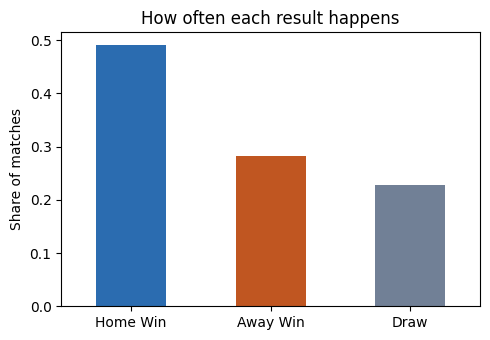

In [ ]:
print("Most common competition types:")
print(raw.tournament.value_counts().head(8))

results = np.where(raw.home_score > raw.away_score, 'Home Win',
           np.where(raw.home_score < raw.away_score, 'Away Win', 'Draw'))
result_counts = pd.Series(results).value_counts(normalize=True)
print("\nOverall result breakdown:")
print(result_counts.round(3))

result_counts.plot(kind='bar', color=['#2b6cb0','#c05621','#718096'], figsize=(5,3.5))
plt.title("How often each result happens")
plt.ylabel("Share of matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Home teams win around 45–48% of matches historically, while draws are the least common. That gives us the baseline we need later: if a model cannot beat always picking home win, it is not adding much value.

## Step 4 — Feature engineering

The raw data has team names, but models need numbers. So we turn each team's recent history into simple stats,
like their recent win rate and goal difference.

We only use data before the match being predicted, so the model does not leak future information.

We also limit the data to matches from 1990 onward, since older results are less relevant to modern teams.


In [ ]:
df = raw[(raw.date < '2026-06-11') & (raw.date >= '1990-01-01')].copy()
print(f"Matches used for training/testing: {len(df):,}")
print("(Cut off before the World Cup started)")

# reshape to one row per team per match
home = df[['date','home_team','away_team','home_score','away_score','neutral']].copy()
home.columns = ['date','team','opponent','goals_for','goals_against','neutral']
away = df[['date','away_team','home_team','away_score','home_score','neutral']].copy()
away.columns = ['date','team','opponent','goals_for','goals_against','neutral']

long = pd.concat([home, away], ignore_index=True).sort_values(['team','date']).reset_index(drop=True)
long['win'] = (long.goals_for > long.goals_against).astype(int)
long['goal_diff'] = long.goals_for - long.goals_against

g = long.groupby('team')
long['form_win_rate'] = g['win'].transform(lambda s: s.shift(1).rolling(10, min_periods=5).mean())
long['form_goal_diff'] = g['goal_diff'].transform(lambda s: s.shift(1).rolling(10, min_periods=5).mean())
long['matches_played_before'] = g.cumcount()

long[['date','team','opponent','form_win_rate','form_goal_diff']].dropna().tail()

Matches used for training/testing: 32,298
(Cut off before the World Cup started — the model never sees 2026 WC results)


,date,team,opponent,form_win_rate,form_goal_diff
64591,2017-06-29,Åland Islands,Ynys Môn,0.3,-0.5
64592,2023-07-09,Åland Islands,Isle of Wight,0.3,-0.5
64593,2023-07-10,Åland Islands,Guernsey,0.3,-0.6
64594,2023-07-11,Åland Islands,Western Isles,0.3,-0.5
64595,2023-07-13,Åland Islands,Falkland Islands,0.2,-0.8


In [ ]:
# rebuild the match-level rows with pre-match form stats
feat = long[['date','team','opponent','goals_for','form_win_rate','form_goal_diff','matches_played_before']]

home_feat = (feat.merge(df[['date','home_team','away_team']], left_on=['date','team','opponent'],
                          right_on=['date','home_team','away_team'])
                  .rename(columns={'form_win_rate':'home_form_win_rate','form_goal_diff':'home_form_goal_diff',
                                    'matches_played_before':'home_matches_played'})
                  [['date','home_team','away_team','home_form_win_rate','home_form_goal_diff','home_matches_played']])

away_feat = (feat.merge(df[['date','home_team','away_team']], left_on=['date','team','opponent'],
                          right_on=['date','away_team','home_team'])
                  .rename(columns={'form_win_rate':'away_form_win_rate','form_goal_diff':'away_form_goal_diff',
                                    'matches_played_before':'away_matches_played'})
                  [['date','home_team','away_team','away_form_win_rate','away_form_goal_diff','away_matches_played']])

matches = df.merge(home_feat, on=['date','home_team','away_team'], how='left')
matches = matches.merge(away_feat, on=['date','home_team','away_team'], how='left')

matches = matches.dropna(subset=['home_form_win_rate','away_form_win_rate'])
matches = matches[(matches.home_matches_played >= 10) & (matches.away_matches_played >= 10)]

matches['result'] = np.where(matches.home_score > matches.away_score, 'home_win',
                     np.where(matches.home_score < matches.away_score, 'away_win', 'draw'))
matches['neutral'] = matches['neutral'].map({True:1, False:0}).fillna(0).astype(int)

print(f"Final training dataset: {len(matches):,} matches with reliable features")
matches[['date','home_team','away_team','home_form_win_rate','away_form_win_rate','result']].tail()

Final training dataset: 30,141 matches with reliable features


,date,home_team,away_team,home_form_win_rate,away_form_win_rate,result
32293,2026-06-09,Iraq,Venezuela,0.5,0.3,away_win
32294,2026-06-10,Bolivia,Algeria,0.3,0.7,away_win
32295,2026-06-10,England,Costa Rica,0.7,0.1,home_win
32296,2026-06-10,Portugal,Nigeria,0.6,0.6,home_win
32297,2026-06-10,Afghanistan,Pakistan,0.1,0.2,away_win


## Step 5 — Split the data and train models

We use a time-based split instead of a random one so the test set behaves like real future matches.

We also compare against a simple baseline: always predicting a home win.


In [ ]:
features = ['home_form_win_rate','home_form_goal_diff','away_form_win_rate','away_form_goal_diff','neutral']
X, y = matches[features], matches['result']

train_mask = matches.date < '2024-01-01'
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print(f"Training on {len(X_train):,} matches (before 2024)")
print(f"Testing on {len(X_test):,} matches (2024 onward)")

baseline_acc = (y_test == 'home_win').mean()
print(f"\nBaseline accuracy if always predicting home win: {baseline_acc:.1%}")

Training on 27,600 matches (before 2024)
Testing on 2,541 matches (2024 onward, model has never seen these)

Naive baseline ('always predict home win') accuracy: 47.5%


### Model 1: Logistic Regression

This is a simple, interpretable baseline model that learns how each feature affects the prediction.


In [6]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
pred_lr = logreg.predict(X_test)

print(f"Logistic Regression accuracy: {accuracy_score(y_test, pred_lr):.1%}")
print(f"(Baseline was {baseline_acc:.1%} — so this is {'better' if accuracy_score(y_test, pred_lr)>baseline_acc else 'not better'} than guessing home win every time)")

Logistic Regression accuracy: 54.4%
(Baseline was 47.5% — so this is better than guessing home win every time)


### Model 2: Random Forest

A Random Forest is a stronger ensemble model that combines many decision trees to make a more stable prediction.


In [7]:
rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print(f"Random Forest accuracy: {accuracy_score(y_test, pred_rf):.1%}")
print("\nFull breakdown by class:")
print(classification_report(y_test, pred_rf, zero_division=0))

Random Forest accuracy: 53.9%

Full breakdown by class:
              precision    recall  f1-score   support

    away_win       0.53      0.41      0.46       733
        draw       0.00      0.00      0.00       602
    home_win       0.54      0.89      0.67      1206

    accuracy                           0.54      2541
   macro avg       0.36      0.43      0.38      2541
weighted avg       0.41      0.54      0.45      2541



This report shows the model is decent at home and away wins, but not great at draws. That is common in football prediction, since draws are harder to predict from simple form features alone.


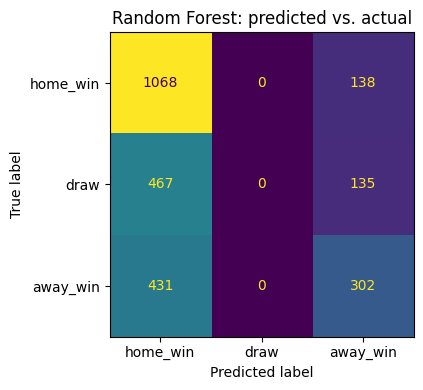

In [8]:
fig, ax = plt.subplots(figsize=(4.5,4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_rf, ax=ax, colorbar=False,
                                          labels=['home_win','draw','away_win'])
plt.title("Random Forest: predicted vs. actual")
plt.tight_layout()
plt.show()

## Step 6 — Which features mattered?

This checks whether the model was focusing on the features we expected.


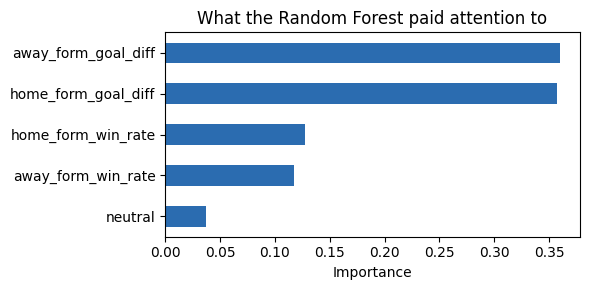

In [9]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values()
importances.plot(kind='barh', color='#2b6cb0', figsize=(6,3))
plt.title("What the Random Forest paid attention to")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Goal difference mattered more than raw win rate, which makes sense because it captures how strongly a team has been performing, not just whether they got the result.


## Step 7 — Use the model to predict World Cup 2026 group matches

We take the actual fixture list and give the model each team's form before the tournament began. It then predicts the likely result for each match without seeing the actual outcome.


In [10]:
# each team's most recent known form, right before the tournament started
latest_form = long.sort_values('date').groupby('team').tail(1).set_index('team')[['form_win_rate','form_goal_diff']]

wc26 = raw[(raw.tournament=='FIFA World Cup') & (raw.date>='2026-06-11')][['date','home_team','away_team']].copy()
wc26 = wc26[wc26.date <= wc26.date.min() + pd.Timedelta(days=15)]  # group stage window

rows = []
for _, r in wc26.iterrows():
    if r.home_team in latest_form.index and r.away_team in latest_form.index:
        rows.append({
            'home_team': r.home_team, 'away_team': r.away_team,
            'home_form_win_rate': latest_form.loc[r.home_team,'form_win_rate'],
            'home_form_goal_diff': latest_form.loc[r.home_team,'form_goal_diff'],
            'away_form_win_rate': latest_form.loc[r.away_team,'form_win_rate'],
            'away_form_goal_diff': latest_form.loc[r.away_team,'form_goal_diff'],
            'neutral': 1
        })
fixtures = pd.DataFrame(rows)

probs = logreg.predict_proba(fixtures[features])
fixtures['prediction'] = logreg.predict(fixtures[features])
for i, c in enumerate(logreg.classes_):
    fixtures[c] = probs[:, i].round(2)

fixtures[['home_team','away_team','prediction','home_win','draw','away_win']].head(20)

,home_team,away_team,prediction,home_win,draw,away_win
0,Mexico,South Africa,home_win,0.45,0.27,0.28
1,South Korea,Czech Republic,home_win,0.42,0.27,0.31
2,Canada,Bosnia and Herzegovina,home_win,0.37,0.28,0.34
3,United States,Paraguay,home_win,0.42,0.26,0.32
4,Qatar,Switzerland,away_win,0.12,0.22,0.66
5,Brazil,Morocco,away_win,0.32,0.30,0.38
6,Haiti,Scotland,away_win,0.31,0.28,0.40
7,Australia,Turkey,away_win,0.32,0.27,0.41
8,Germany,Curaçao,home_win,0.63,0.23,0.15
9,Ivory Coast,Ecuador,home_win,0.53,0.26,0.22


These predictions are still simple. The model only sees recent results, not squad quality, injuries, or team reputation, so it is a basic forecast rather than a full football analytics model.


## Recap: the six steps, and where to go next

| Step | What we did |
|---|---|
| 1. Define the problem | Classify each match as home win, draw, or away win |
| 2. Get data | Use a real public results dataset |
| 3. Explore the data | Check the result distribution and establish a baseline |
| 4. Engineer features | Build rolling form features from recent matches |
| 5. Train and evaluate | Compare a simple logistic model to a stronger random forest |
| 6. Use the model | Apply it to real 2026 World Cup fixtures |

From here, the project could be improved with Elo ratings, head-to-head stats, or a stronger gradient-boosting model.